In [ ]:
# %pip install kagglehub matplotlib pillow scikit-learn ultralytics albumentations 

In [81]:
import kagglehub
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
import shutil
import ultralytics
from ultralytics import YOLO
import albumentations
from ultralytics.data.utils import check_det_dataset, verify_image_label
from ultralytics.data import YOLODataset
from ultralytics.cfg import DEFAULT_CFG
from ultralytics.utils import IterableSimpleNamespace
import random
import time

# **EDA**

In [ ]:
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}
EPOCHS = 50
BATCH_SIZE = 15
RANDOM_SEED = 42

In [4]:
path = kagglehub.dataset_download(
    "ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"
)

DATA_DIR = Path(path)

print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

100%|██████████| 133M/133M [00:04<00:00, 33.0MB/s] 

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1
Dataset exists: True


In [5]:
print("\n========== DATASET STRUCTURE ==========")

for item in sorted(DATA_DIR.rglob("*")):
    relative_path = item.relative_to(DATA_DIR)
    depth = len(relative_path.parts)

    if depth <= 3:
        if item.is_dir():
            print(f"[DIR]  {relative_path}/")
        else:
            print(f"[FILE] {relative_path}")




========== DATASET STRUCTURE ==========
[DIR]  Train/
[DIR]  Train/Glioma/
[DIR]  Train/Glioma/images/
[DIR]  Train/Glioma/labels/
[DIR]  Train/Meningioma/
[DIR]  Train/Meningioma/images/
[DIR]  Train/Meningioma/labels/
[DIR]  Train/No Tumor/
[DIR]  Train/No Tumor/images/
[DIR]  Train/No Tumor/labels/
[DIR]  Train/Pituitary/
[DIR]  Train/Pituitary/images/
[DIR]  Train/Pituitary/labels/
[DIR]  Val/
[DIR]  Val/Glioma/
[DIR]  Val/Glioma/images/
[DIR]  Val/Glioma/labels/
[DIR]  Val/Meningioma/
[DIR]  Val/Meningioma/images/
[DIR]  Val/Meningioma/labels/
[DIR]  Val/No Tumor/
[DIR]  Val/No Tumor/images/
[DIR]  Val/No Tumor/labels/
[DIR]  Val/Pituitary/
[DIR]  Val/Pituitary/images/
[DIR]  Val/Pituitary/labels/


In [6]:
train_dir = DATA_DIR / "Train"

class_folders = sorted(
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
)

CLASS_NAMES = {
    class_id: class_name
    for class_id, class_name in enumerate(class_folders)
}

print(CLASS_NAMES)

{0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


In [7]:
image_paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

label_paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
)

In [8]:
print("\n========== DATASET COUNTS ==========")
print("Number of images:", len(image_paths))
print("Number of TXT files:", len(label_paths))


========== DATASET COUNTS ==========
Number of images: 5249
Number of TXT files: 5249


In [9]:
print("========== Examples ==========")
print("\nExample images:")
for p in image_paths[:5]:
    print(p.relative_to(DATA_DIR))

print("\nExample annotation files:")
for p in label_paths[:5]:
    print(p.relative_to(DATA_DIR))



========== Examples ==========

Example images:
Train/Glioma/images/Te-glTr_0000.jpg
Train/Glioma/images/Te-glTr_0005.jpg
Train/Glioma/images/Te-glTr_0007.jpg
Train/Glioma/images/Te-gl_0014.jpg
Train/Glioma/images/Te-gl_0015.jpg

Example annotation files:
Train/Glioma/labels/Te-glTr_0000.txt
Train/Glioma/labels/Te-glTr_0005.txt
Train/Glioma/labels/Te-glTr_0007.txt
Train/Glioma/labels/Te-gl_0014.txt
Train/Glioma/labels/Te-gl_0015.txt


In [10]:
print("\nClass mapping:")
for class_id, class_name in sorted(CLASS_NAMES.items()):
    print(f"{class_id}: {class_name}")



Class mapping:
0: Glioma
1: Meningioma
2: No Tumor
3: Pituitary


In [11]:
def common_parent_length(image_path, label_path):
    image_parts = image_path.relative_to(DATA_DIR).parts[:-1]
    label_parts = label_path.relative_to(DATA_DIR).parts[:-1]

    common = 0

    for a, b in zip(image_parts, label_parts):
        if a != b:
            break
        common += 1

    return common

In [12]:
labels_by_stem = defaultdict(list)

for label_path in label_paths:
    labels_by_stem[label_path.stem].append(label_path)

image_label_pairs = []
missing_labels = []
ambiguous_images = []

# count1 = 0
# count2 = 0

for image_path in image_paths:
    candidates = labels_by_stem.get(image_path.stem, [])

    if len(candidates) == 1:
        image_label_pairs.append((image_path, candidates[0]))
        # count1 += 1
    elif len(candidates) == 0:
        missing_labels.append(image_path)
        # count2 += 1

    else:
        image_parts = image_path.relative_to(DATA_DIR).parts[:-1]

        ranked = sorted(
            candidates,
            key=lambda label_path: common_parent_length(image_path, label_path),
            reverse=True
        )

        best_score = common_parent_length(ranked[0])

        if (
            best_score > 0
            and (
                len(ranked) == 1
                or common_parent_length(ranked[1]) < best_score
            )
        ):
            image_label_pairs.append((image_path, ranked[0]))
        else:
            ambiguous_images.append(image_path)

In [13]:
print("\n========== IMAGE-LABEL MATCHING ==========")
print("Matched pairs:", len(image_label_pairs))
print("Images without labels:", len(missing_labels))
print("Images with ambiguous labels:", len(ambiguous_images))



========== IMAGE-LABEL MATCHING ==========
Matched pairs: 5247
Images without labels: 2
Images with ambiguous labels: 0


In [14]:
if missing_labels:
    print("\nExamples of images without labels:")
    for p in missing_labels[:10]:
        print(p.relative_to(DATA_DIR))

if ambiguous_images:
    print("\nExamples with ambiguous labels:")
    for p in ambiguous_images[:10]:
        print(p.relative_to(DATA_DIR))


Examples of images without labels:
Val/No Tumor/images/image(55).jpg
Val/No Tumor/images/image(61).jpg


In [15]:
def read_yolo_labels(label_path):

    annotations = []
    invalid_lines = []

    with open(label_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            line = line.strip()

            # Empty lines are ignored
            if not line:
                continue

            values = line.split()

            if len(values) != 5:
                invalid_lines.append(
                    (line_number, "Expected exactly 5 values")
                )
                continue

            try:
                class_value = float(values[0])
                coordinates = list(map(float, values[1:]))

                if not class_value.is_integer():
                    invalid_lines.append(
                        (line_number, "Class ID must be an integer")
                    )
                    continue

                class_id = int(class_value)
                x_center, y_center, width, height = coordinates

            except ValueError:
                invalid_lines.append(
                    (line_number, "Non-numeric value")
                )
                continue

            if class_id not in CLASS_NAMES:
                invalid_lines.append(
                    (line_number, f"Unknown class ID: {class_id}")
                )
                continue

            if not all(
                0 <= value <= 1
                for value in (x_center, y_center, width, height)
            ):
                invalid_lines.append(
                    (line_number, "Coordinates must be between 0 and 1")
                )
                continue

            if width <= 0 or height <= 0:
                invalid_lines.append(
                    (line_number, "Width and height must be positive")
                )
                continue

            annotations.append(
                (class_id, x_center, y_center, width, height)
            )

    return annotations, invalid_lines


In [16]:
# Display a real annotation file
print("\n========== EXAMPLE YOLO ANNOTATION ==========")

example_found = False

for image_path, label_path in image_label_pairs:
    try:
        annotations, invalid_lines = read_yolo_labels(label_path)

        if annotations:
            print("Image:", image_path.relative_to(DATA_DIR))
            print("Label:", label_path.relative_to(DATA_DIR))
            print("Raw annotation content:")
            print(label_path.read_text(encoding="utf-8"))

            print("\nInterpreted annotations:")
            for annotation in annotations:
                class_id, xc, yc, w, h = annotation
                print(
                    f"Class: {CLASS_NAMES[class_id]}, "
                    f"x_center={xc}, y_center={yc}, "
                    f"width={w}, height={h}"
                )

            example_found = True
            break

    except OSError as error:
        print(f"Could not read {label_path}: {error}")

if not example_found:
    print("No valid non-empty annotation found.")


========== EXAMPLE YOLO ANNOTATION ==========
Image: Train/Glioma/images/Te-glTr_0000.jpg
Label: Train/Glioma/labels/Te-glTr_0000.txt
Raw annotation content:
0 0.555664 0.653320 0.146484 0.193359


Interpreted annotations:
Class: Glioma, x_center=0.555664, y_center=0.65332, width=0.146484, height=0.193359


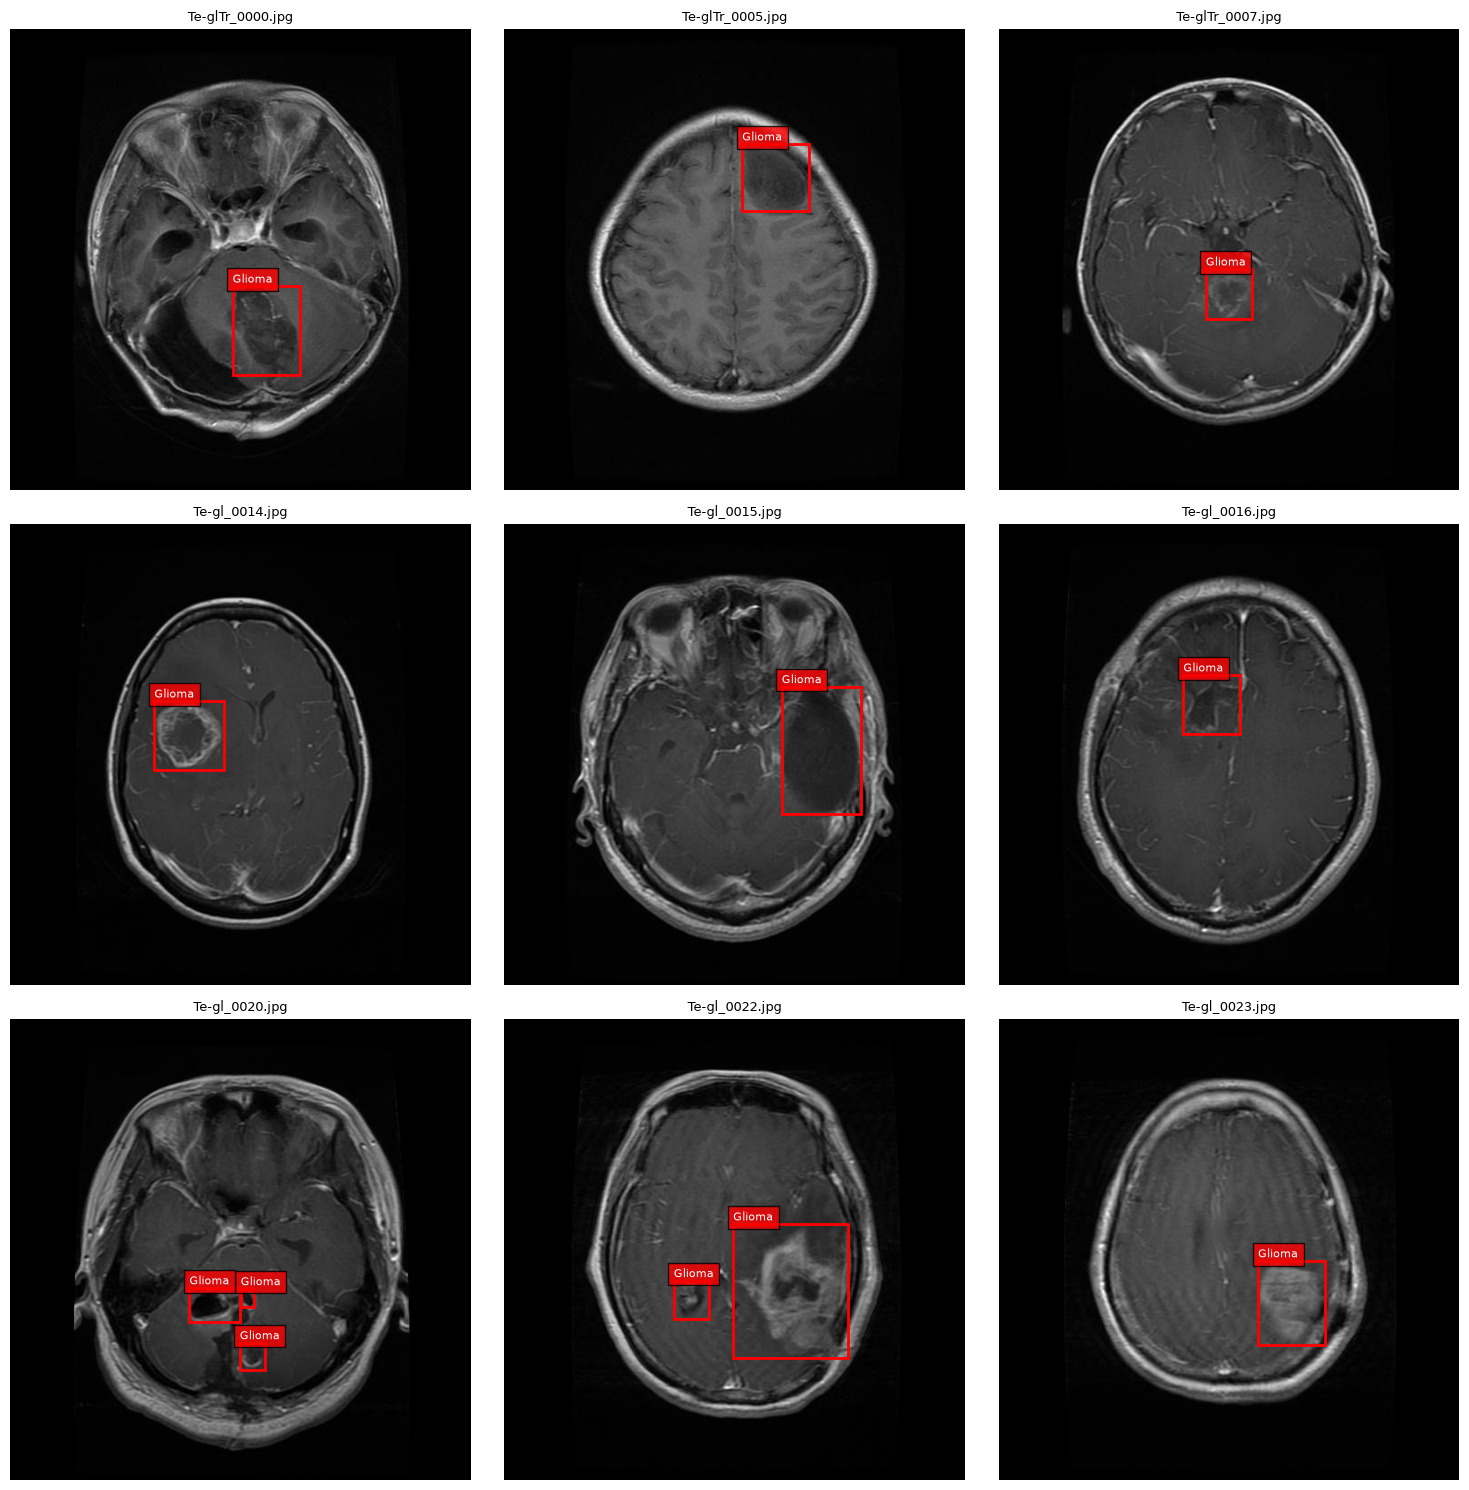

In [17]:
def show_mri_samples(pairs, n=9):
    samples = pairs[:n]

    if not samples:
        print("No matched image-label pairs to display.")
        return

    _ , axes = plt.subplots(3, 3, figsize=(15, 15))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (image_path, label_path) in zip(axes, samples):

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        image_width, image_height = image.size
        annotations, invalid_lines = read_yolo_labels(label_path)

        ax.imshow(image)
        ax.set_title(image_path.name, fontsize=9)

        for class_id, xc, yc, w, h in annotations:
            # Convert normalized YOLO coordinates to pixels
            x_min = (xc - w / 2) * image_width
            y_min = (yc - h / 2) * image_height
            box_width = w * image_width
            box_height = h * image_height

            rect = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            class_name = CLASS_NAMES[class_id]

            ax.text(
                x_min,
                max(0, y_min - 4),
                class_name,
                color="white",
                fontsize=8,
                bbox={
                    "facecolor": "red",
                    "alpha": 0.8
                }
            )

        if invalid_lines:
            print(
                f"{label_path.name}: "
                f"{len(invalid_lines)} invalid annotation line(s)"
            )

    plt.tight_layout()
    plt.show()


show_mri_samples(image_label_pairs, n=9)

In [18]:
images_per_class = Counter()
boxes_per_class = Counter()

empty_label_count = 0
invalid_line_count = 0
unreadable_label_count = 0
unreadable_image_count = 0

for image_path, label_path in image_label_pairs:
    try:
        # Check that the image can actually be opened
        with Image.open(image_path) as image:
            image.verify()

        annotations, invalid_lines = read_yolo_labels(label_path)
        invalid_line_count += len(invalid_lines)

        # An empty file, or a file with no valid annotations,
        # is counted here for preliminary inspection.
        if not annotations:
            empty_label_count += 1
            continue

        # Count every valid bounding box
        for class_id, xc, yc, w, h in annotations:
            boxes_per_class[class_id] += 1

        # Count a class only once per image
        classes_in_image = {
            class_id
            for class_id, xc, yc, w, h in annotations
        }

        for class_id in classes_in_image:
            images_per_class[class_id] += 1

    except OSError as error:
        unreadable_image_count += 1
        print(f"Unreadable image {image_path}: {error}")

    except (ValueError, UnicodeError) as error:
        unreadable_label_count += 1
        print(f"Unreadable label {label_path}: {error}")

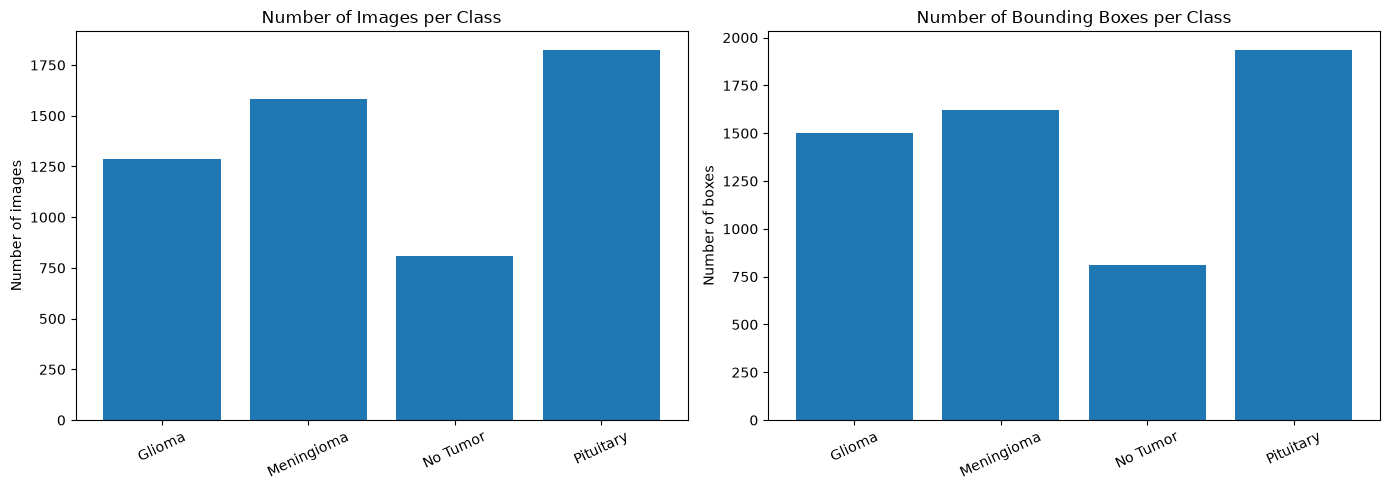

In [19]:
class_ids = sorted(CLASS_NAMES.keys())
class_labels = [CLASS_NAMES[class_id] for class_id in class_ids]

image_counts = [
    images_per_class[class_id]
    for class_id in class_ids
]

box_counts = [
    boxes_per_class[class_id]
    for class_id in class_ids
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_labels, image_counts)
axes[0].set_title("Number of Images per Class")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(class_labels, box_counts)
axes[1].set_title("Number of Bounding Boxes per Class")
axes[1].set_ylabel("Number of boxes")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


In [20]:
print("\n========== FINAL DATASET SUMMARY ==========")

print("Total images discovered:", len(image_paths))
print("Total TXT files discovered:", len(label_paths))
print("Matched image-label pairs:", len(image_label_pairs))
print("Images without matching labels:", len(missing_labels))
print("Images with ambiguous labels:", len(ambiguous_images))
print("Empty or annotation-free label files:", empty_label_count)
print("Invalid annotation lines:", invalid_line_count)
print("Unreadable images:", unreadable_image_count)
print("Unreadable annotation files:", unreadable_label_count)

print("\nClass distribution:")
print("-" * 55)

for class_id in class_ids:
    print(
        f"{CLASS_NAMES[class_id]:12} | "
        f"Images: {images_per_class[class_id]:5} | "
        f"Boxes: {boxes_per_class[class_id]:5}"
    )

print("-" * 55)



========== FINAL DATASET SUMMARY ==========
Total images discovered: 5249
Total TXT files discovered: 5249
Matched image-label pairs: 5247
Images without matching labels: 2
Images with ambiguous labels: 0
Empty or annotation-free label files: 1
Invalid annotation lines: 0
Unreadable images: 0
Unreadable annotation files: 0

Class distribution:
-------------------------------------------------------
Glioma       | Images:  1287 | Boxes:  1502
Meningioma   | Images:  1582 | Boxes:  1624
No Tumor     | Images:   809 | Boxes:   809
Pituitary    | Images:  1825 | Boxes:  1936
-------------------------------------------------------


In [21]:
for image_path in missing_labels:
    print(image_path.relative_to(DATA_DIR))

Val/No Tumor/images/image(55).jpg
Val/No Tumor/images/image(61).jpg


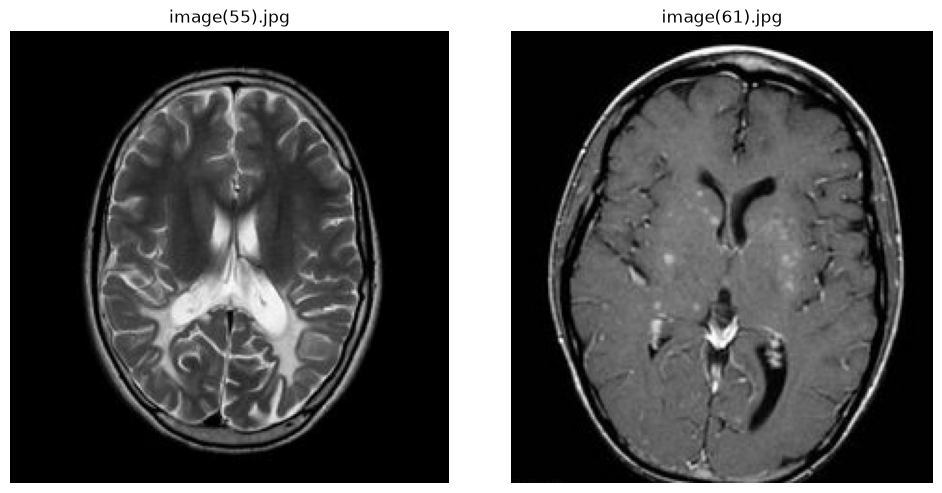

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, image_path in zip(axes, missing_labels):
    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
empty_label_pairs = []

for image_path, label_path in image_label_pairs:
    annotations, _ = read_yolo_labels(label_path)

    if not annotations:
        empty_label_pairs.append((image_path, label_path))

print("Images with empty annotations:", len(empty_label_pairs))

for image_path, label_path in empty_label_pairs:
    print("Image:", image_path.relative_to(DATA_DIR))
    print("Label:", label_path.relative_to(DATA_DIR))

Images with empty annotations: 1
Image: Val/Glioma/images/gg (342).jpg
Label: Val/Glioma/labels/gg (342).txt


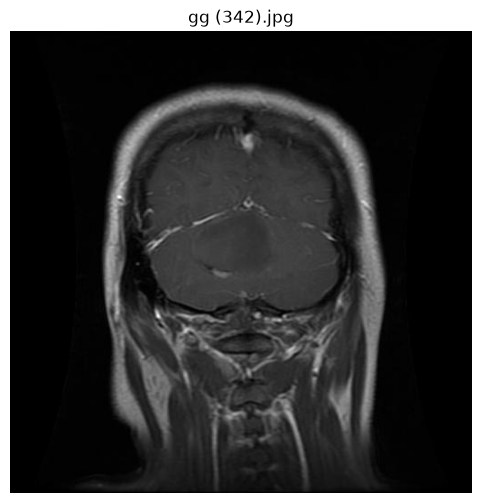

In [24]:
image_path, label_path = empty_label_pairs[0]

with Image.open(image_path) as image:
    plt.figure(figsize=(6, 6))
    plt.imshow(image.convert("RGB"))
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

# **Cleaning**

In [25]:
#! work in progress

In [26]:
train_pairs = [
    (image_path, label_path)
    for image_path, label_path in image_label_pairs
    if "Train" in image_path.parts
    and (image_path, label_path) not in empty_label_pairs
]

print("Training pairs:", len(train_pairs))

Training pairs: 4737


In [27]:
val_pairs = [
    (image_path, label_path)
    for image_path, label_path in image_label_pairs
    if "Val" in image_path.parts
]

print("Validation image-label pairs:", len(val_pairs))

Validation image-label pairs: 510


In [28]:
val_folder_counts = Counter(
    image_path.parent.parent.name
    for image_path, label_path in val_pairs
)

for class_name, count in sorted(val_folder_counts.items()):
    print(f"{class_name}: {count}")

Glioma: 136
Meningioma: 140
No Tumor: 98
Pituitary: 136


In [29]:
clean_val_pairs = [
    (image_path, label_path)
    for image_path, label_path in val_pairs
    if (image_path, label_path) not in empty_label_pairs
]

print("Pairs ready for splitting:", len(clean_val_pairs))

Pairs ready for splitting: 509


# **Splitin Data**

In [30]:
def split_dataset(pairs, test_size=0.5, random_state=42):
    folder_labels = [ image_path.parent.parent.name for image_path, label_path in pairs ]

    val_pairs, test_pairs = train_test_split( pairs, 
                                             test_size=test_size, 
                                             random_state=random_state, 
                                             shuffle=True, 
                                             stratify=folder_labels )

    return val_pairs, test_pairs

In [31]:
val_split_pairs, test_split_pairs = split_dataset(clean_val_pairs)

print("Validation pairs:", len(val_split_pairs))
print("Test pairs:", len(test_split_pairs))

Validation pairs: 254
Test pairs: 255


In [32]:
# save the spliting


# create the folders
OUTPUT_DIR = Path("dataset")

for split in ["train", "val", "test"]:
    for folder in ["images", "labels"]:
        for class_name in CLASS_NAMES.values():
            (OUTPUT_DIR / split / folder / class_name).mkdir( parents=True, exist_ok=True )

In [33]:

# reusable copying function
def copy_pairs(pairs, split_name):
    for image_path, label_path in pairs:
        class_name = image_path.parent.parent.name

        image_destination = ( OUTPUT_DIR / split_name / "images" / class_name / image_path.name )

        label_destination = ( OUTPUT_DIR / split_name / "labels" / class_name / label_path.name )

        shutil.copy2(image_path, image_destination)
        shutil.copy2(label_path, label_destination)

In [34]:
# copy the pairs
copy_pairs(train_pairs, "train")
copy_pairs(val_split_pairs, "val")
copy_pairs(test_split_pairs, "test")

In [ ]:
yaml_content = f"""
path: {OUTPUT_DIR.resolve().as_posix()}

train: train/images
val: val/images
test: test/images

nc: 4

names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary
"""

yaml_path = OUTPUT_DIR / "data.yaml"
yaml_path.write_text(yaml_content.strip() + "\n")

# read the yaml file

print(yaml_path.read_text())

path: /dataset

train: train/images
val: val/images
test: test/images

nc: 4

names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary



# **Data Augmentation**

In [ ]:
AUGMENTATION_CONFIG = {
    # Geometric transformations
    "degrees": 5.0,
    "translate": 0.05,
    "scale": 0.10,

    # Color and brightness
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.10,

    # Flipping
    "fliplr": 0.0,
    "flipud": 0.0,

    # Mosaic
    "mosaic": 0.0,

    # Custom brightness and contrast
    "augmentations": [
        albumentations.RandomBrightnessContrast(
            brightness_limit=0.10,
            contrast_limit=0.10,
            p=0.5
        )
    ]
}

In [ ]:
# Load dataset configuration
data = check_det_dataset(str(OUTPUT_DIR / "data.yaml"))

# Prepare augmentation settings
hyp = IterableSimpleNamespace(
    **{
        **vars(DEFAULT_CFG),
        **AUGMENTATION_CONFIG
    }
)

# Create an augmented training dataset
augmented_dataset = YOLODataset( img_path=data["train"], 
                                data=data, 
                                task="detect", 
                                imgsz=640, 
                                augment=True, 
                                hyp=hyp )

print("Training samples:", len(augmented_dataset))

Fast image access ✅ (ping: 0.0±0.0 ms, read: 659.2±234.5 MB/s, size: 25.2 KB)
Scanning /dataset/train/labels/Glioma.cache... 4737 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4737/4737 2.5Git/s 0.0s
albumentations: RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.1, 0.1), contrast_limit=(-0.1, 0.1), ensure_safe_range=False)
Training samples: 4737


### Data Augmentation Justification

Data augmentation is applied **only to the training set** to improve the model's ability to generalize to unseen MRI images. Validation and test datasets remain unchanged to ensure a fair evaluation.

**Selected transformations:**

- **Rotation (`degrees=5.0`):** Applies small rotations to simulate slight variations in image orientation while preserving anatomical structures.
- **Scale (`scale=0.10`):** Simulates moderate zoom variations, helping the model recognize tumors at slightly different apparent sizes.
- **Translation (`translate=0.05`):** Slightly shifts images to make the model more robust to variations in tumor position.
- **Brightness (`hsv_v=0.10`):** Simulates small variations in MRI intensity.
- **Contrast (`contrast_limit=0.10`):** Helps the model handle differences in contrast between MRI images.
- **Random Brightness and Contrast:** An additional Albumentations transformation applies brightness and contrast variations with a probability of 50%.

**Disabled transformations:**

- **Horizontal Flip (`fliplr=0.0`):** Disabled because flipping may reverse the left-right orientation of the brain, potentially changing anatomically meaningful information.
- **Vertical Flip (`flipud=0.0`):** Disabled to avoid generating anatomically unrealistic image orientations.
- **Strong Rotations:** Avoided because large rotations may produce unrealistic MRI orientations and alter the anatomical context.
- **Hue (`hsv_h=0.0`) and Saturation (`hsv_s=0.0`):** Disabled because MRI images are grayscale. Hue and saturation transformations are not meaningful for this type of image.

**Mosaic (`mosaic=0.0`):**

Mosaic augmentation is disabled. It combines multiple images into a single training image. Although YOLOv8 automatically adjusts bounding-box coordinates during this transformation, combining images can reduce the apparent size of tumors and disrupt their original anatomical context. Since preserving the spatial context of brain MRI images is important for this task, Mosaic is not used.

**Validation and Test:**

No data augmentation is applied to validation or test datasets (`augment=False`). This ensures that model evaluation is performed on images that retain their original appearance.

# **Model**

In [74]:
model = YOLO("yolov8n.pt")

In [ ]:
model = YOLO("yolov8n.pt")

start_time = time.perf_counter()

results = model.train( data=str(OUTPUT_DIR / "data.yaml"), 
                      epochs=EPOCHS, 
                      imgsz=640, 
                      batch=BATCH_SIZE, **{ key: value for key, value in AUGMENTATION_CONFIG.items() if key != "augmentations" } )

end_time = time.perf_counter()

training_duration = end_time - start_time

print(f"Training duration: {training_duration / 60:.2f} minutes")

best_model = YOLO(
    str(results.save_dir / "weights" / "best.pt")
)


Ultralytics 8.4.193 🚀 Python-3.12.15 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 4080, 15946MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimi

In [ ]:
best_model = YOLO(str(results.save_dir / "weights" / "best.pt"))

test_results = best_model.val( data=str(OUTPUT_DIR / "data.yaml"), 
                              split="test", 
                              imgsz=640, 
                              batch=16 )

Ultralytics 8.4.193 🚀 Python-3.12.15 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 4080, 15946MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1300.3±421.0 MB/s, size: 27.2 KB)
val: Scanning /dataset/test/labels/Glioma.cache... 255 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 255/255 178.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 10.0it/s 1.6s0.1s
                   all        255        275      0.948      0.961      0.967      0.738
                Glioma         68         75      0.887       0.96      0.969      0.697
            Meningioma         70         71       0.98      0.986      0.994      0.797
              No Tumor         49         49          1      0.992      0.995      0.771
             Pituitary         78         80      0.924      0.906      0.912      0.687
Speed: 1.5ms preprocess, 0.9m


# **Visualize Predictions vs Ground Truth**


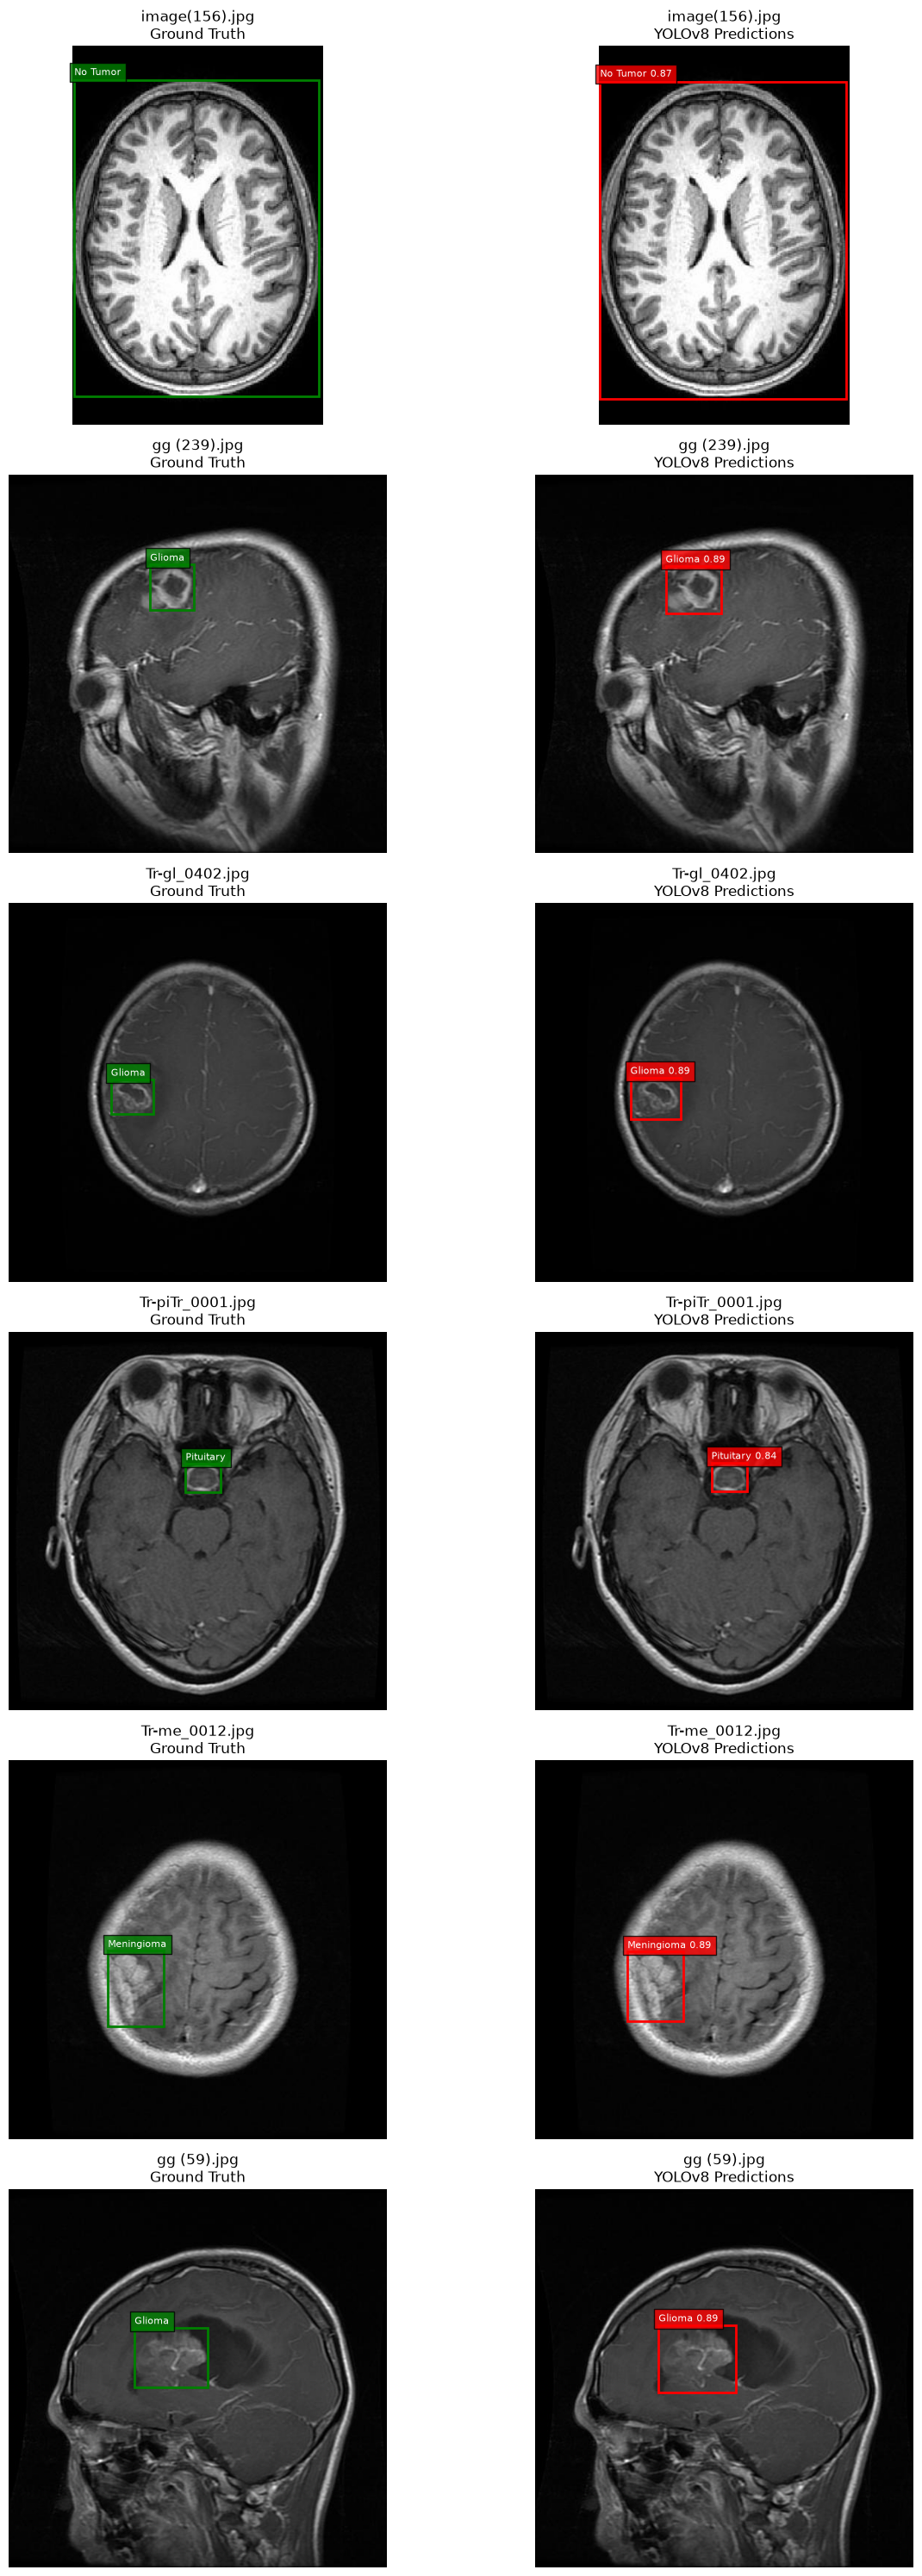

In [80]:

# Class names
CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

# Test image directory
TEST_IMAGE_DIR = OUTPUT_DIR / "test" / "images"

# Get all test images
test_images = sorted(
    path for path in TEST_IMAGE_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

# Select 6 random images
random.seed(RANDOM_SEED)

sample_images = random.sample(
    test_images,
    min(6, len(test_images))
)

if not sample_images:
    print("No test images found.")

else:

    def draw_boxes(ax, boxes, class_ids, color, confidences=None):

        for i, box in enumerate(boxes):

            x1, y1, x2, y2 = box

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor=color,
                facecolor="none"
            )

            ax.add_patch(rect)

            class_id = int(class_ids[i])
            label = CLASS_NAMES[class_id]

            if confidences is not None:
                label += f" {confidences[i]:.2f}"

            ax.text(
                x1,
                max(0, y1 - 5),
                label,
                color="white",
                fontsize=8,
                bbox={
                    "facecolor": color,
                    "alpha": 0.8
                }
            )

    # Create comparison figure
    fig, axes = plt.subplots(
        len(sample_images),
        2,
        figsize=(14, 5 * len(sample_images))
    )

    if len(sample_images) == 1:
        axes = axes.reshape(1, 2)

    for i, image_path in enumerate(sample_images):

        # Load original image
        with Image.open(image_path) as source:
            image = source.convert("RGB")

        width, height = image.size

        # Find corresponding YOLO label
        relative_path = image_path.relative_to(TEST_IMAGE_DIR)

        label_path = (
            OUTPUT_DIR / "test" / "labels" /
            relative_path.parent / f"{image_path.stem}.txt"
        )

        # Read ground-truth annotations
        gt_boxes = []
        gt_classes = []

        if label_path.exists():

            with open(label_path, "r") as file:

                for line in file:

                    values = line.split()

                    if len(values) != 5:
                        continue

                    class_id, x_center, y_center, box_width, box_height = (
                        map(float, values)
                    )

                    # Convert normalized YOLO coordinates to pixels
                    x1 = (x_center - box_width / 2) * width
                    y1 = (y_center - box_height / 2) * height
                    x2 = (x_center + box_width / 2) * width
                    y2 = (y_center + box_height / 2) * height

                    gt_boxes.append([x1, y1, x2, y2])
                    gt_classes.append(int(class_id))

        # Run model prediction
        prediction = best_model.predict(
            source=str(image_path),
            imgsz=640,
            conf=0.25,
            verbose=False
        )[0]

        # Extract predictions safely
        if prediction.boxes is not None and len(prediction.boxes) > 0:

            pred_boxes = prediction.boxes.xyxy.cpu().numpy()
            pred_classes = prediction.boxes.cls.cpu().numpy().astype(int)
            pred_confidences = prediction.boxes.conf.cpu().numpy()

        else:

            pred_boxes = []
            pred_classes = []
            pred_confidences = []

        # Display ground truth
        ax_gt = axes[i, 0]
        ax_gt.imshow(image)

        draw_boxes(
            ax_gt,
            gt_boxes,
            gt_classes,
            color="green"
        )

        ax_gt.set_title(f"{image_path.name}\nGround Truth")
        ax_gt.axis("off")

        # Display predictions
        ax_pred = axes[i, 1]
        ax_pred.imshow(image)

        draw_boxes(
            ax_pred,
            pred_boxes,
            pred_classes,
            color="red",
            confidences=pred_confidences
        )

        ax_pred.set_title(f"{image_path.name}\nYOLOv8 Predictions")
        ax_pred.axis("off")

    plt.tight_layout()
    plt.show()


# **Training and Validation Curves**

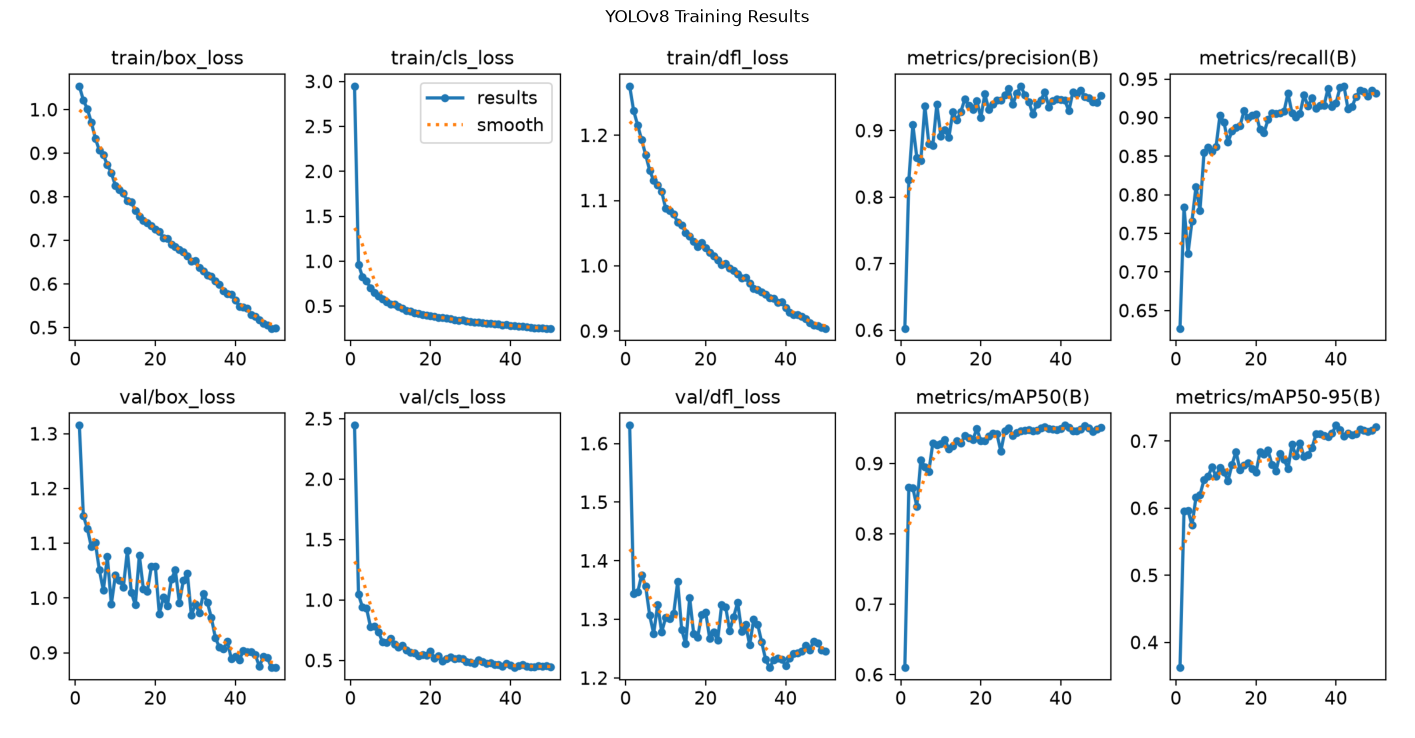

In [ ]:
RUN_DIR = Path(results.save_dir)

results_plot = RUN_DIR / "results.png"

if results_plot.exists():
    with Image.open(results_plot) as image:
        plt.figure(figsize=(18, 12))
        plt.imshow(image)
        plt.axis("off")
        plt.title("YOLOv8 Training Results")
        plt.show()
else:
    print("results.png was not found.")

